# Quand Newton tourne en rond

Au TP3 (exercice 4.3), la méthode de Newton appliquée à $x^3 - 2x + 2$ en partant de 0 ne
converge pas : elle fait 0, 1, 0, 1… indéfiniment. Le TP s'arrêtait sur ce constat. Ce projet
part de là, avec trois questions :

1. Est-ce un accident du point de départ 0, ou toute une région de points de départ
   tombe-t-elle dans ce piège ?
2. Si on prend un point de départ au hasard, quelle chance a-t-on d'être piégé ?
3. Qu'a de particulier $c = 2$ ? Que se passe-t-il pour $x^3 - 2x + c$ quand $c$ varie ?

Les fonctions sont dans les fichiers `.py` du dossier, ce carnet les utilise et commente les
résultats. numpy sert à appliquer le même calcul à des centaines de milliers de points d'un
coup ; les algorithmes eux-mêmes (Horner, Newton, pivot de Gauss, dichotomie) sont ceux des
TP. `np.roots` et `np.polyfit` ne servent que de points de comparaison.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from polynomes import evaluer, deriver, racines, newton_securise
from systemes import moindres_carres
from bassins import grille, iterer, classer, finit_sur, couronne, bord, compter_boites
from famille import (orbite_zero, converge_depuis_zero, tours_depuis_zero, periode,
                     bifurcation, retour, retour_bis, superstables)

P = [2, -2, 0, 1]   # x^3 - 2x + 2
Q = [-1, 0, 0, 1]   # z^3 - 1, pour comparer

## 1. Le point de départ

On refait l'expérience du TP3, puis on regarde ce que deviennent quelques points de départ
voisins de 0 et de 1.

In [2]:
def trajet(P, x, tours):
    """Liste des itérés de Newton depuis x."""
    dP = deriver(P)
    res = [x]
    for _ in range(tours):
        x = x - evaluer(P, x) / evaluer(dP, x)
        res.append(x)
    return res

print([round(x, 6) for x in trajet(P, 0.0, 6)])
for x0 in (0.1, -0.15, 0.9, 1.1, 0.3, -1.0):
    print(f"depuis {x0:>5} : finit sur {[round(x, 6) for x in trajet(P, x0, 60)[-2:]]}")

[0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0]
depuis   0.1 : finit sur [1.0, 0.0]
depuis -0.15 : finit sur [-1.769292, -1.769292]
depuis   0.9 : finit sur [-1.769292, -1.769292]
depuis   1.1 : finit sur [1.0, 0.0]
depuis   0.3 : finit sur [-1.769292, -1.769292]
depuis  -1.0 : finit sur [-1.769292, -1.769292]


Depuis 0,1 ou 1,1, l'orbite finit elle aussi sur le cycle 0, 1 : l'échec du TP3 n'est pas
lié au point 0 exactement. Mais depuis −0,15 ou 0,9, tout aussi proches, on trouve la racine
réelle. La zone piégée a donc l'air petite, et sa forme n'est pas évidente. Pour la voir, il
faut regarder tout le plan : les points de départ complexes comptent aussi, puisque le
polynôme a deux racines complexes.

## 2. Les trois racines

`racines` applique Newton depuis un point complexe, divise le polynôme par $(x - r)$ avec
Horner, et recommence sur le quotient. On vérifie par les relations entre coefficients et
racines : pour $x^3 + 0x^2 - 2x + 2$, la somme des racines vaut $0$ et leur produit $-2$.

In [3]:
R = racines(P)
for r in R:
    print(f"{r:.12f}   |P(r)| = {abs(evaluer(P, r)):.1e}")
print("somme :", sum(R), "  produit :", R[0] * R[1] * R[2])
print("np.roots :", np.roots(P[::-1]))

0.884646177119+0.589742805022j   |P(r)| = 0.0e+00
0.884646177119-0.589742805022j   |P(r)| = 0.0e+00
-1.769292354239+0.000000000000j   |P(r)| = 2.2e-16
somme : 0j   produit : (-1.9999999999999998+0j)
np.roots : [-1.76929235+0.j          0.88464618+0.58974281j  0.88464618-0.58974281j]


## 3. Quand décider qu'un point est piégé ?

On dit qu'un point de départ arrive sur une racine quand un itéré passe à moins de $10^{-8}$
d'elle. Reste à choisir combien de tours on attend avant de déclarer le point piégé. Plutôt
que de fixer ce nombre au hasard, je mesure la proportion de points pas encore arrivés après
$K$ tours, sur une grille de $400 \times 400$ points de $[-2{,}5 ; 2{,}5]^2$, pour $z^3 - 1$
(qui n'a pas de cycle piège, tout le monde le dit) et pour notre polynôme.

In [4]:
Z0 = grille(-2.5, 2.5, -2.5, 2.5, 400)
paliers = [5, 10, 20, 40, 80, 160, 320]
print("K :".rjust(14), "".join(f"{K:>9}" for K in paliers))
for nom, poly in (("z^3 - 1", Q), ("x^3 - 2x + 2", P)):
    _, nb = classer(poly, racines(poly), Z0, tours=320)
    print(f"{nom:>13} ", "".join(f"{np.mean(nb > K):>9.4%}" for K in paliers))

           K :         5       10       20       40       80      160      320


      z^3 - 1   82.7900% 11.7612%  0.7075%  0.0037%  0.0000%  0.0000%  0.0000%


 x^3 - 2x + 2   79.5125%  9.6338%  0.9275%  0.7400%  0.7400%  0.7400%  0.7400%


Pour $z^3 - 1$ la proportion tombe à zéro : tous les points finissent par arriver, certains
lentement. Pour $x^3 - 2x + 2$ elle se stabilise à 0,74 % dès 40 tours et ne bouge plus
jusqu'à 320 : ces points n'arriveront jamais. Dans la suite j'attends 100 tours, plus du
double du palier.

Que deviennent ces points ? On les itère et on regarde où ils sont.

In [5]:
classe, nb = classer(P, R, Z0, tours=100)
fin = iterer(P, Z0[classe == -1], 100)
print(len(fin), "points piégés, positions finales :", np.unique(np.round(fin, 8)))

1184 points piégés, positions finales : [0.+0.j 1.+0.j]


Tous finissent exactement sur 0 ou sur 1 : il n'y a qu'un seul piège, le cycle du TP3.

## 4. Les bassins d'attraction

Chaque point de départ est coloré selon la racine qu'il atteint (les croix blanches), en noir
s'il finit sur le cycle 0, 1.

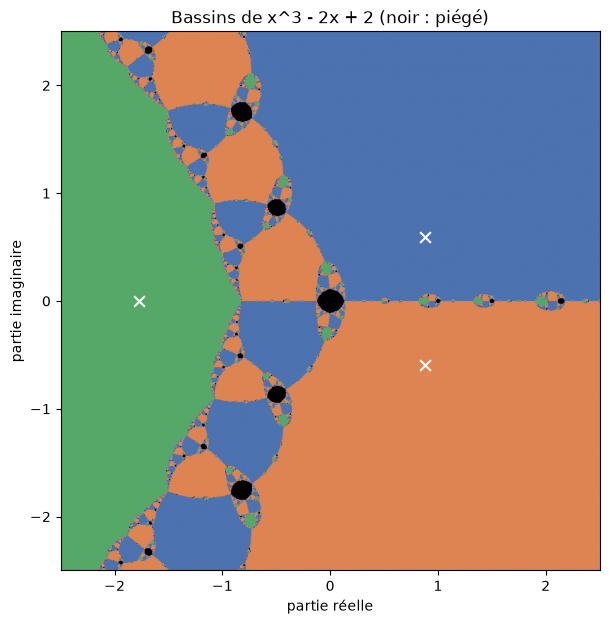

In [6]:
couleurs = ListedColormap(["black", "#4c72b0", "#dd8452", "#55a868"])

def dessiner(classe, cadre, titre, fichier=None):
    plt.figure(figsize=(7, 7))
    plt.imshow(classe, cmap=couleurs, vmin=-1, vmax=2, origin="lower", extent=cadre)
    x1, x2, y1, y2 = cadre
    for r in R:
        if x1 <= r.real <= x2 and y1 <= r.imag <= y2:
            plt.scatter([r.real], [r.imag], marker="x", color="white", s=60)
    plt.xlabel("partie réelle")
    plt.ylabel("partie imaginaire")
    plt.title(titre)
    if fichier:
        plt.savefig(fichier, dpi=90, bbox_inches="tight")
    plt.show()

cadre = (-2.5, 2.5, -2.5, 2.5)
classe, nb = classer(P, R, grille(*cadre, 800), tours=100)
dessiner(classe, cadre, "Bassins de x^3 - 2x + 2 (noir : piégé)", "figures/bassins.png")

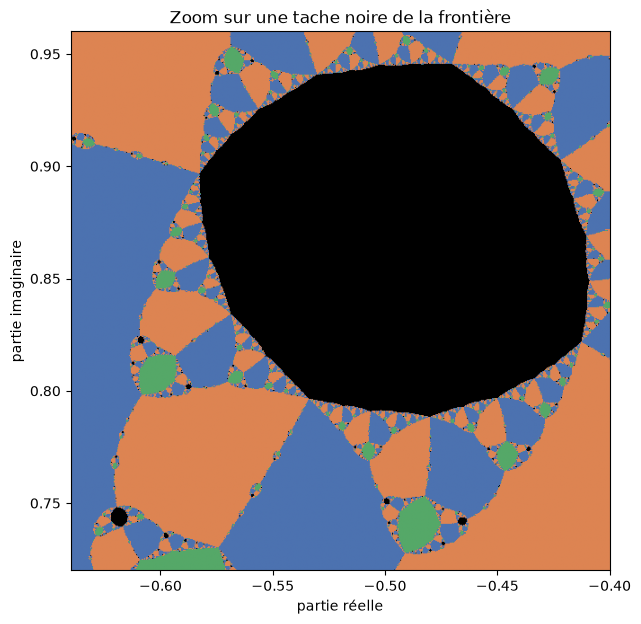

In [7]:
cadre = (-0.64, -0.40, 0.72, 0.96)
classe_z, _ = classer(P, R, grille(*cadre, 600), tours=150)
dessiner(classe_z, cadre, "Zoom sur une tache noire de la frontière")

Les deux grosses taches noires autour de 0 et de 1 sont le piège du TP3 : c'est une vraie
région, pas un point. Il y en a des copies plus petites partout sur les frontières entre
couleurs, et le zoom montre que le motif se répète : chaque tache noire est entourée des trois
couleurs et d'autres taches plus petites. Entre deux bassins il y a toujours le troisième, ce
qui veut dire qu'une frontière n'est jamais une simple ligne.

## 5. Le piège est-il petit ?

Ma première idée était de mesurer l'aire de la zone noire. Sur $[-2{,}5 ; 2{,}5]^2$ elle vaut
environ 0,19 ; je pensais que le piège était limité à un voisinage de 0 et de 1, et que ce
nombre répondait à la question. Par acquit de conscience j'ai agrandi la fenêtre :

In [8]:
for a in (1, 2, 2.5, 3, 4, 6, 10):
    pieges = finit_sur(P, grille(-a, a, -a, a, 500), [0, 1])
    print(f"fenêtre [-{a}, {a}]^2 : aire piégée {pieges.mean() * (2 * a) ** 2:.3f}")

fenêtre [-1, 1]^2 : aire piégée 0.094


fenêtre [-2, 2]^2 : aire piégée 0.169


fenêtre [-2.5, 2.5]^2 : aire piégée 0.186


fenêtre [-3, 3]^2 : aire piégée 0.301


fenêtre [-4, 4]^2 : aire piégée 0.341


fenêtre [-6, 6]^2 : aire piégée 0.674


fenêtre [-10, 10]^2 : aire piégée 1.546


L'aire ne se stabilise pas, elle augmente avec la fenêtre : il y a des points piégés loin de
l'origine. Pour comprendre pourquoi, regardons ce que fait un pas de Newton sur un point très
éloigné.

In [9]:
dP = deriver(P)
for z in (10, 100j, 1000 * np.exp(1j), 1e6):
    print(z, " N(z) / z =", (z - evaluer(P, z) / evaluer(dP, z)) / z)

10  N(z) / z = 0.6704697986577182
100j  N(z) / z = (0.6666222251849877-6.666222251849876e-07j)
(540.3023058681398+841.4709848078965j)  N(z) / z = (0.6666664823723183-4.040378858245408e-07j)
1000000.0  N(z) / z = 0.666666666667111


Loin de l'origine, $N(z) \approx \frac{2}{3} z$ : le terme $z^3$ écrase les autres, et
$z - \frac{z^3}{3z^2} = \frac{2}{3} z$. Un point à distance $1{,}5\,r$ arrive donc en un tour
là où était un point à distance $r$, avec la même direction. Si c'est vrai, l'image doit être
la même à toutes les échelles : $z$ et $1{,}5\,z$ ont le même sort. Je le teste sur 100 000
points tirés au hasard, à différentes distances.

In [10]:
rng = np.random.default_rng(1)
for r in (3, 10, 100, 1e4):
    Z = couronne(r, 100_000, rng)
    a, b = finit_sur(P, Z, [0, 1]), finit_sur(P, 1.5 * Z, [0, 1])
    print(f"r = {r:>7g} : piégés {a.sum()} et {b.sum()}, même sort pour {np.mean(a == b):.4%} des points")

r =       3 : piégés 514 et 513, même sort pour 99.3570% des points


r =      10 : piégés 479 et 475, même sort pour 99.8800% des points


r =     100 : piégés 435 et 434, même sort pour 99.9910% des points


r =   10000 : piégés 445 et 445, même sort pour 100.0000% des points


À partir de $r = 100$ l'accord est presque parfait, et total à $r = 10^4$. La zone noire
se répète à l'identique, agrandie de 1,5 à chaque fois : elle s'étend jusqu'à l'infini, et
son aire est infinie. La bonne question devient donc une proportion : dans une couronne
$r \le |z| < 1{,}5\,r$, quelle part des points est piégée ? C'est une estimation de
Monte-Carlo (TP6), avec une incertitude de l'ordre de $2\sqrt{p(1-p)/n}$.

Premier essai, en tirant les points uniformément dans la couronne :

In [11]:
rng = np.random.default_rng(0)
n = 100_000
for r in (10, 100, 1000, 1e4, 1e6):
    p = finit_sur(P, couronne(r, n, rng, log=False), [0, 1]).mean()
    print(f"couronne [{r:g}, {1.5 * r:g}] : {p:.3%} +- {2 * np.sqrt(p * (1 - p) / n):.3%}")

couronne [10, 15] : 0.400% +- 0.040%


couronne [100, 150] : 0.456% +- 0.043%


couronne [1000, 1500] : 0.583% +- 0.048%


couronne [10000, 15000] : 0.416% +- 0.041%


couronne [1e+06, 1.5e+06] : 0.540% +- 0.046%


Les valeurs ne concordent pas entre elles, nettement au delà des barres d'erreur, alors que les
couronnes sont toutes des copies agrandies les unes des autres. Mon explication : tirer
uniformément en surface favorise l'extérieur de la couronne (il y a plus de place), et ce qui
se trouve à l'extérieur dépend de la position de $r$ dans le cycle des agrandissements par
1,5. Si c'est ça, la proportion ne dépend que de la « phase » $\varphi$ telle que
$r = r_0 \times 1{,}5^{\varphi}$, et deux $r_0$ très différents doivent donner la même courbe.
Et en tirant le rayon uniformément en échelle logarithmique, ce qui respecte les
agrandissements, la proportion doit devenir constante.

uniforme en surface, r0 = 1000 : de 0.379% à 0.596%


uniforme en surface, r0 = 1e6 : de 0.374% à 0.576%


uniforme en log du rayon, r0 = 1000 : de 0.435% à 0.479%


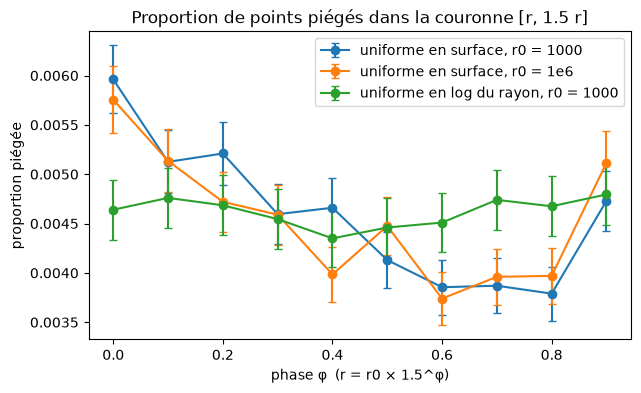

tirage logarithmique, 400 000 points : 0.469% +- 0.022%


In [12]:
phases = np.arange(0, 1, 0.1)
n = 200_000
plt.figure(figsize=(7, 4))
essais = ((1000, False, "uniforme en surface, r0 = 1000"),
          (1e6, False, "uniforme en surface, r0 = 1e6"),
          (1000, True, "uniforme en log du rayon, r0 = 1000"))
for r0, log, nom in essais:
    props = np.array([finit_sur(P, couronne(r0 * 1.5 ** f, n, rng, log), [0, 1], tours=100).mean()
                      for f in phases])
    # barres à deux écarts-types
    plt.errorbar(phases, props, yerr=2 * np.sqrt(props * (1 - props) / n), marker="o", capsize=3, label=nom)
    print(f"{nom} : de {props.min():.3%} à {props.max():.3%}")
plt.xlabel("phase φ  (r = r0 × 1.5^φ)")
plt.ylabel("proportion piégée")
plt.legend()
plt.title("Proportion de points piégés dans la couronne [r, 1.5 r]")
plt.show()

Z = couronne(1000, 400_000, rng, log=True)
p = finit_sur(P, Z, [0, 1]).mean()
print(f"tirage logarithmique, 400 000 points : {p:.3%} +- {2 * np.sqrt(p * (1 - p) / len(Z)):.3%}")

Les deux courbes « uniforme en surface » ont le même profil, autour de 0,6 % pour $\varphi = 0$,
sous 0,4 % vers $\varphi = 0{,}7$, puis remontée, alors que $r_0$ est mille fois plus grand pour
l'une que pour l'autre : la proportion dépend bien de la phase seulement. Leurs petits écarts
restent de l'ordre des barres d'erreur. Le tirage logarithmique, lui, reste entre 0,43 % et
0,48 % sans tendance : constant, aux fluctuations de Monte-Carlo près.

Réponse à la question 2 : environ **un point de départ sur 200** finit dans le piège, aussi
loin qu'on parte. Le chiffre exact dépend de ce qu'on appelle « au hasard » : uniforme en
surface, il oscille entre 0,4 % et 0,6 % selon la couronne, sans jamais tendre vers zéro.

## 6. La frontière est-elle une courbe ?

Le zoom de la partie 4 suggère que la frontière entre bassins est plus « épaisse » qu'une
ligne. On peut le mesurer par comptage de boîtes : on découpe l'image en boîtes de $t$ pixels
de côté et on compte celles qui contiennent un morceau de frontière. Pour une courbe, ce
nombre double quand $t$ est divisé par 2 ; pour une surface il est multiplié par 4. En
général $N(t) \approx C\,t^{-D}$, et la pente $D$ de $\log N$ en fonction de $\log(1/t)$ est
la dimension. La pente est obtenue par moindres carrés, avec le pivot de Gauss du TP4.

Avant de croire le résultat, on valide la méthode sur un cercle et un carré, dont la
frontière est de dimension 1.

In [13]:
n = 1024
tailles = [2, 4, 8, 16, 32, 64]
Z0 = grille(-2, 2, -2, 2, n)
images = {
    "cercle": (np.abs(Z0) < 1.3).astype(int),
    "carré": ((abs(Z0.real) < 1.1) & (abs(Z0.imag) < 1.1)).astype(int),
    "z^3 - 1": classer(Q, racines(Q), Z0, tours=100)[0],
    "x^3 - 2x + 2": classer(P, R, Z0, tours=100)[0],
}
xs = [np.log(1 / t) for t in tailles]
for nom, im in images.items():
    N = [compter_boites(bord(im), t) for t in tailles]
    ys = [np.log(v) for v in N]
    D, _ = moindres_carres(xs, ys)
    locales = np.diff(ys) / np.diff(xs)
    print(f"{nom:>13} : D = {D:.3f}  (np.polyfit {np.polyfit(xs, ys, 1)[0]:.3f})"
          f"  pentes entre tailles voisines {np.round(locales, 2)}")

       cercle : D = 0.964  (np.polyfit 0.964)  pentes entre tailles voisines [0.96 0.96 1.   0.95 0.93]
        carré : D = 1.000  (np.polyfit 1.000)  pentes entre tailles voisines [0.99 0.99 1.02 1.04 0.92]
      z^3 - 1 : D = 1.413  (np.polyfit 1.413)  pentes entre tailles voisines [1.37 1.41 1.44 1.39 1.44]
 x^3 - 2x + 2 : D = 1.353  (np.polyfit 1.353)  pentes entre tailles voisines [1.33 1.35 1.35 1.4  1.31]


Le cercle et le carré donnent bien une dimension proche de 1, ce qui valide le comptage. La
frontière des bassins de $x^3 - 2x + 2$ donne environ 1,35 : plus qu'une courbe, moins qu'une
surface. C'est la traduction chiffrée de « entre deux bassins il y a toujours le troisième ».
La pente des moindres carrés est la même que celle de `np.polyfit`.

La mesure a ses limites : six tailles de boîtes seulement (de 2 à 64 pixels), et les pentes
entre tailles voisines varient de 1,31 à 1,40. Je donnerais donc $D = 1{,}35 \pm 0{,}05$,
sans pouvoir le comparer à une valeur théorique.

## 7. Pourquoi c = 2 ?

Notons $N(z) = z - p(z)/p'(z)$ le pas de Newton. Sa dérivée se calcule :

$$N'(z) = 1 - \frac{p'(z)^2 - p(z)\,p''(z)}{p'(z)^2} = \frac{p(z)\,p''(z)}{p'(z)^2}.$$

Elle s'annule aux racines de $p$ (c'est pour ça que Newton converge si vite près d'une racine)
et là où $p''(z) = 0$. Pour $p(x) = x^3 - 2x + c$, $p''(x) = 6x$ : c'est le point $0$, quel
que soit $c$. Pour $c = 2$, le cycle $0 \to 1 \to 0$ passe par ce point où $N' = 0$, et attire
donc aussi fort qu'une racine.

En cherchant pourquoi, je suis tombé sur un théorème de Fatou : tout cycle attractif d'une
fraction rationnelle comme $N$ attire au moins un point où $N'$ s'annule. Les racines s'attirent
elles-mêmes, il ne reste que $0$. Donc il existe un piège si et seulement si **l'orbite de 0 ne
va pas vers une racine**. Je ne sais pas démontrer ce théorème, mais je peux le confronter aux
mesures : pour plusieurs valeurs de $c$, je compare la proportion de points non convergents sur
une grille (coûteux) au sort de la seule orbite de 0 (immédiat).

In [14]:
Z0 = grille(-3, 3, -3, 3, 300)
print("     c | grille : non convergents | orbite de 0 après 500 tours | après 4000 tours")
for c in (0, 1.0895, 1.2055, 1.352, 1.5, 1.935, 1.94, 1.945, 1.955, 1.98, 2, 2.01, 2.1, 2.652, 2.8):
    Pc = [c, -2, 0, 1]
    with np.errstate(all="ignore"):
        Zf = iterer(Pc, Z0, 300)
        frac = 1 - np.mean(np.abs(evaluer(Pc, Zf)) < 1e-9)
    etats = []
    for tours in (500, 4000):
        if converge_depuis_zero(np.array([c]), tours)[0]:
            etats.append("racine")
        else:
            q = periode(c, tours)
            etats.append(f"cycle de période {q}" if q else "ni racine ni cycle")
    print(f"{c:>6} | {frac:>23.4%} | {etats[0]:>27} | {etats[1]}")

     c | grille : non convergents | orbite de 0 après 500 tours | après 4000 tours


     0 |                 0.0000% |                      racine | racine


1.0895 |                 0.0000% |          ni racine ni cycle | racine


1.2055 |                 0.0378% |          ni racine ni cycle | cycle de période 6


 1.352 |                 0.0089% |         cycle de période 16 | cycle de période 16


   1.5 |                 0.0000% |                      racine | racine


... (6 outputs left out)

  2.01 |                 0.8222% |          cycle de période 2 | cycle de période 2


   2.1 |                 0.0000% |                      racine | racine


 2.652 |                 0.0022% |         cycle de période 12 | cycle de période 12


   2.8 |                 0.0000% |          ni racine ni cycle | cycle de période 7


La grille et l'orbite de 0 sont d'accord sur les cas nets : pas de piège pour $c = 0$, $1{,}5$
ou $2{,}1$ ; un piège de 0,3 % à 0,8 % de la grille entre $c = 1{,}955$ et $2{,}01$, où 0 finit
sur un cycle de période 4 puis 2. Mais le tableau montre aussi trois pièges du test « orbite
de 0 », que j'ai découverts en le remplissant.

- **Les faux piégés.** Pour $c = 1{,}0895$, l'orbite de 0 n'a pas trouvé de racine en 500 tours,
  et j'ai d'abord cru à une petite fenêtre de piège. Avec 4000 tours elle converge. Ce $c$ est
  juste au-dessus de $\sqrt{32/27} \approx 1{,}0887$, où deux racines réelles se rejoignent :
  il reste une « racine fantôme » près de laquelle l'orbite traîne très longtemps. Aucun nombre
  de tours fixe ne met complètement à l'abri de ce genre d'erreur.
- **Les orbites qui errent.** Pour $c = 1{,}935$ ou $1{,}94$, l'orbite de 0 ne trouve ni racine
  ni cycle, même après 4000 tours : elle erre sans se fixer. Il n'y a alors pas de cycle
  attractif, et la grille ne trouve aucun point piégé. Le test « 0 ne converge pas » dit donc
  « peut-être un piège », pas « un piège ».
- **Les pièges trop petits pour la grille.** Pour $c = 2{,}8$, 0 finit sur un cycle de période 7 :
  il y a un piège, mais ses taches sont plus petites qu'un pixel et la grille ne voit rien. Pour
  $c = 2{,}652$ ou $1{,}352$ (périodes 12 et 16), elle n'en voit que 2 ou 8 points sur 90 000.
  Là, c'est le test de l'orbite de 0 qui a raison.

Au passage, pour $c = 1{,}2055$ et $c = 2{,}8$, 500 tours ne suffisaient pas à l'orbite pour
rejoindre son cycle : encore une question de nombre de tours.

Avec ces réserves, on peut balayer $c$ très finement sans calculer une seule image. Il suffit
de traiter $c \ge 0$ : $p_{-c}(-x) = -p_c(x)$, donc la dynamique pour $-c$ est le miroir de
celle pour $c$.

In [15]:
C = np.linspace(0, 3, 30_001)
libre = ~converge_depuis_zero(C, 4000)
# regroupe les c consécutifs dont l'orbite ne converge pas en fenêtres
fenetres = []
for i in np.flatnonzero(libre):
    if fenetres and i == fenetres[-1][1] + 1:
        fenetres[-1][1] = i
    else:
        fenetres.append([i, i])
print(len(fenetres), "fenêtres sur [0, 3], dont celles plus larges que 2e-4 :")
for i, j in fenetres:
    if C[j] - C[i] >= 2e-4:
        milieu = (C[i] + C[j]) / 2
        print(f"  [{C[i]:.4f}, {C[j]:.4f}]  période au milieu : {periode(milieu, 6000, qmax=128)}")

35 fenêtres sur [0, 3], dont celles plus larges que 2e-4 :
  [1.2049, 1.2067]  période au milieu : 6
  [1.3517, 1.3528]  période au milieu : 8
  [1.4564, 1.4569]  période au milieu : 10
  [1.9173, 2.0162]  période au milieu : 4
  [2.1685, 2.1688]  période au milieu : 14
  [2.4151, 2.4197]  période au milieu : 10
  [2.6514, 2.6530]  période au milieu : 12
  [2.7997, 2.8002]  période au milieu : 14


35 fenêtres en tout, mais une seule grande, $[1{,}917 ; 2{,}016]$, qui contient $c = 2$ ; les
autres sont étroites, avec des cycles de périodes plus grandes. Le piège du TP3 n'est donc pas une
curiosité isolée, mais ce n'est pas non plus la règle : pour la plupart des $c$, Newton n'a pas
de piège.

## 8. La cascade autour de c = 2

Dans la grande fenêtre, la période change avec $c$ (2 à $c = 2$, 4 à $c = 1{,}955$). Pour voir
toute la structure, je trace, pour chaque $c$, les positions où l'orbite de 0 revient une fois
installée (64 positions après 3000 tours). Un cycle de période 2 donne 2 points, un cycle de
période 4 en donne 4, une orbite qui erre en donne 64 éparpillés.

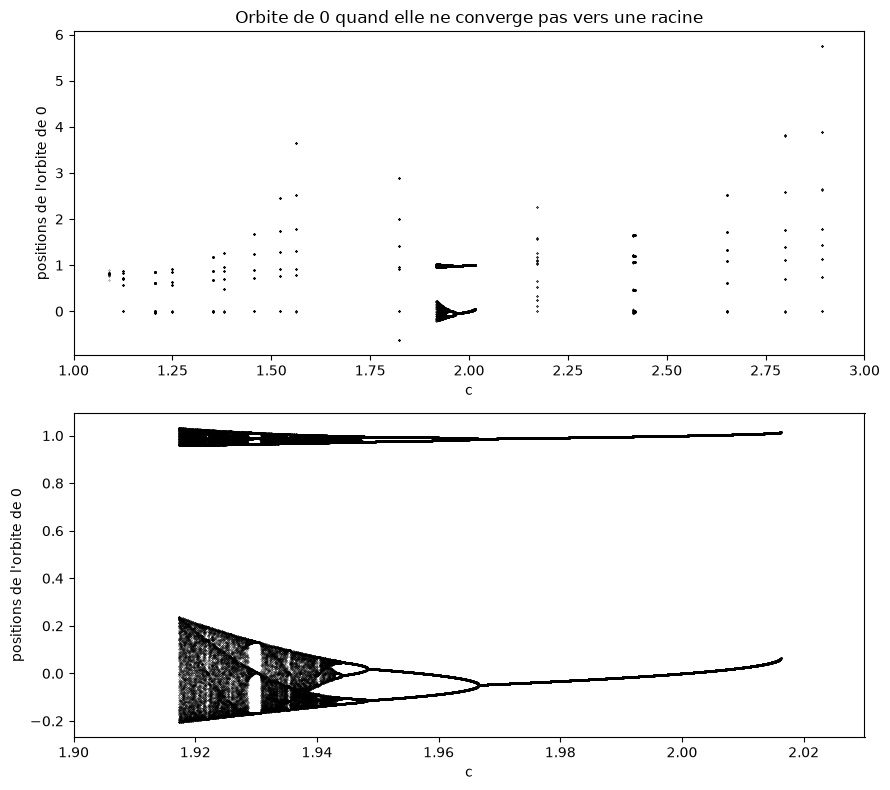

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(9, 8))
for ax, (c1, c2) in zip(axes, ((1.0, 3.0), (1.90, 2.03))):
    C = np.linspace(c1, c2, 3000)
    B = bifurcation(C, tours=3000, garder=64)
    libre = ~converge_depuis_zero(C, 3000)
    ax.scatter(np.tile(C[libre], B.shape[0]), B[:, libre].ravel(), s=0.05, color="black")
    ax.set_xlim(c1, c2)
    ax.set_xlabel("c")
    ax.set_ylabel("positions de l'orbite de 0")
axes[0].set_title("Orbite de 0 quand elle ne converge pas vers une racine")
plt.tight_layout()
plt.savefig("figures/bifurcation.png", dpi=90, bbox_inches="tight")
plt.show()

En haut, les fenêtres de la partie 7 apparaissent comme des colonnes de points. En bas, le
zoom sur la grande fenêtre : en partant de la droite, un cycle de période 2, qui se dédouble en
période 4, puis 8, 16… de plus en plus vite, jusqu'à une zone où l'orbite erre. C'est
le même dessin que le doublement de période de la suite logistique, l'exemple classique de
ce phénomène.

Pour la suite logistique, les valeurs du paramètre où la période double se rapprochent selon
un rapport qui tend vers la constante de Feigenbaum $\delta = 4{,}669\,201\ldots$, et on dit
que ce nombre est universel. Je voulais voir s'il apparaît aussi ici. Plutôt que les points de
dédoublement, difficiles à localiser (l'orbite y converge très lentement), j'utilise les $c$
où 0 fait partie du cycle de période $2^k$, notés $s_k$ : ce sont les zéros de la fonction
$c \mapsto N_c^{2^k}(0)$, que l'on trouve par dichotomie (TP3). $s_1 = 2$ par construction.

In [17]:
t0 = time.perf_counter()
s = superstables(16, retour)
s_bis = superstables(16, retour_bis)
print(f"calculé en {time.perf_counter() - t0:.1f} s")
print(" k | période |          s_k          |  s_(k-1) - s_k  | rapport des écarts | écart entre les deux formules")
for k in sorted(s):
    ligne = f"{k:>2} | {2 ** k:>7} | {s[k]:.16f} |"
    if k >= 2:
        ligne += f" {s[k - 1] - s[k]:>15.3e} |"
    if k >= 3:
        ligne += f" {(s[k - 2] - s[k - 1]) / (s[k - 1] - s[k]):>18.7f} | {abs(s[k] - s_bis[k]):.1e}"
    print(ligne)

calculé en 3.3 s
 k | période |          s_k          |  s_(k-1) - s_k  | rapport des écarts | écart entre les deux formules
 1 |       2 | 2.0000000000000000 |
 2 |       4 | 1.9573421159924873 |       4.266e-02 |
 3 |       8 | 1.9461256198669123 |       1.122e-02 |          3.8031381 | 4.4e-16
 4 |      16 | 1.9436331500371966 |       2.492e-03 |          4.5001532 | 4.4e-16
 5 |      32 | 1.9430955496958511 |       5.376e-04 |          4.6362877 | 8.9e-16
 6 |      64 | 1.9429802295226501 |       1.153e-04 |          4.6618066 | 8.9e-16
 7 |     128 | 1.9429555233746427 |       2.471e-05 |          4.6676711 | 2.2e-15
 8 |     256 | 1.9429502316955904 |       5.292e-06 |          4.6688674 | 3.1e-15
 9 |     512 | 1.9429490983628090 |       1.133e-06 |          4.6691308 | 2.2e-15
10 |    1024 | 1.9429488556368439 |       2.427e-07 |          4.6691864 | 6.2e-15
11 |    2048 | 1.9429488036523352 |       5.198e-08 |          4.6691980 | 1.0e-14
12 |    4096 | 1.9429487925188322 |   

Le rapport des écarts monte vers 4,6692 et l'atteint à $k = 11$ ou $12$ : c'est la constante
de Feigenbaum, à six chiffres près, sortie d'une méthode de résolution d'équations. L'explication
que j'ai trouvée : ce qui compte pour l'universalité, c'est que le point critique soit
« quadratique », c'est-à-dire $N'(0) = 0$ mais $N''(0) \ne 0$. Ici $N''(0) = p(0)\,p^{(3)}(0) / p'(0)^2
= 6c/4 \ne 0$, comme pour la suite logistique en son sommet.

Au delà de $k = 12$ le rapport se dégrade (4,66927, puis 4,66899, 4,66957, 4,6754). La dernière
colonne dit pourquoi : $s_k$ calculé avec deux formules équivalentes du pas de Newton,
$z - p(z)/p'(z)$ et $(2z^3 - c)/(3z^2 - 2)$, diffère de quelques $10^{-15}$ jusqu'à $k = 10$,
puis jusqu'à $4 \times 10^{-14}$, à cause des arrondis accumulés sur des milliers de pas. Or
les écarts entre $s_k$ successifs tombent sous $10^{-8}$ à partir de $k = 13$ : une erreur de
$10^{-14}$ sur chacun fausse leur rapport dès le cinquième ou sixième chiffre. Les flottants de 16 chiffres limitent donc $\delta$ à 6 chiffres ; pour
aller plus loin, il faudrait calculer avec plus de chiffres (module `decimal`, TP1), ce que je
n'ai pas fait.

## 9. Et si c est complexe ?

Rien n'empêche de prendre $c$ complexe et de refaire le test de l'orbite de 0 pour chaque point
d'un rectangle du plan des $c$. Noir : l'orbite de 0 ne trouve pas de racine en 200 tours (400
pour le zoom). Les autres couleurs indiquent le nombre de tours qu'il lui a fallu.

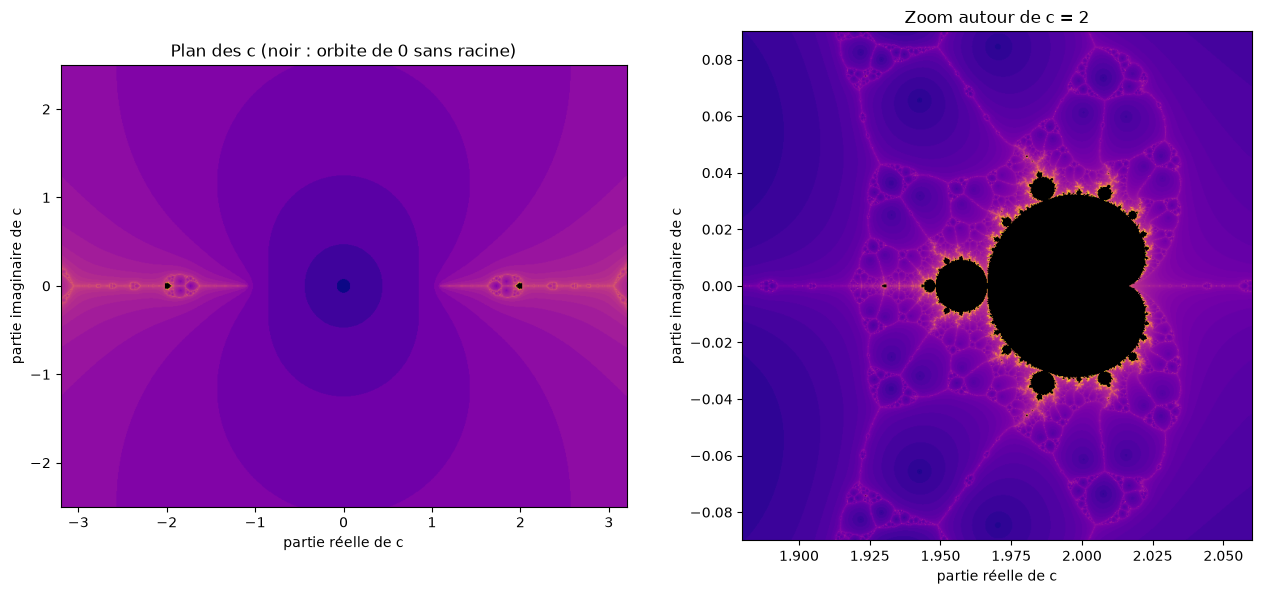

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, cadre, tours in zip(axes, ((-3.2, 3.2, -2.5, 2.5), (1.88, 2.06, -0.09, 0.09)), (200, 400)):
    nb = tours_depuis_zero(grille(*cadre, 700), tours)
    image = np.where(nb > tours, np.nan, np.log(nb))
    ax.set_facecolor("black")  # les nan (pas de racine) restent transparents, donc noirs
    ax.imshow(image, cmap="plasma", origin="lower", extent=cadre)
    ax.set_xlabel("partie réelle de c")
    ax.set_ylabel("partie imaginaire de c")
axes[0].set_title("Plan des c (noir : orbite de 0 sans racine)")
axes[1].set_title("Zoom autour de c = 2")
plt.tight_layout()
plt.savefig("figures/parametres.png", dpi=90, bbox_inches="tight")
plt.show()

Autour de $c = 2$ apparaît une copie de l'ensemble de Mandelbrot. Elle colle avec ce qu'on a
mesuré sur l'axe réel : la grande cardioïde correspond au cycle de période 2 et se termine à
droite en pointe vers $2{,}016$, le bord de la fenêtre ; le premier disque à gauche, centré
près de $1{,}957$, correspond à la période 4 et contient $s_2 = 1{,}9573$. La petite tache
vers $1{,}93$, plus à gauche, est la fenêtre de période 6 visible sur le diagramme de
bifurcation, avec sa propre copie miniature. J'ai appris ensuite que ces copies dans la méthode de Newton sont connues depuis
les expériences sur ordinateur de Curry, Garnett et Sullivan (1983).

## 10. Un Newton qui ne se fait pas piéger

Conséquence pratique de tout ça : un Newton « nu » ne peut pas être utilisé sans garde-fou,
même sur un polynôme de degré 3, et le nombre maximal de tours ne suffit pas (il signale
l'échec mais ne le répare pas). Pour une racine réelle, on sait toujours trouver un intervalle
$[a, b]$ où $p$ change de signe. `newton_securise` fait un pas de Newton s'il tombe dans
l'intervalle, un pas de dichotomie sinon, et resserre l'intervalle à chaque tour : il ne peut
pas tourner en rond. Je compare les deux sur 601 points de départ réels de $[-3, 3]$.

In [19]:
def newton_nu(P, x, tol=1e-12, tours=100):
    """Newton sans garde-fou : (racine, tours) ou (None, tours) en cas d'échec."""
    dP = deriver(P)
    for k in range(tours):
        d = evaluer(dP, x)
        if d == 0:
            return None, k
        y = x - evaluer(P, x) / d
        if abs(y - x) <= tol * max(1.0, abs(y)):
            return y, k + 1
        x = y
    return None, tours

departs = [float(x) for x in np.linspace(-3, 3, 601)]
print("    c | Newton nu : échecs, tours moyen / max | sécurisé : échecs, tours moyen / max")
for c in (0.5, 1.0895, 1.935, 1.955, 1.98, 2.0):
    Pc = [c, -2, 0, 1]
    nu = [newton_nu(Pc, x) for x in departs]
    sur = [newton_securise(Pc, -3.0, 3.0, x) for x in departs]
    t_nu = [k for r, k in nu if r is not None]
    t_sur = [k for r, k in sur if abs(evaluer(Pc, r)) < 1e-9]
    print(f"{c:>5} | {601 - len(t_nu):>9} {np.mean(t_nu):>13.1f} / {max(t_nu):<3}"
          f"           | {601 - len(t_sur):>9} {np.mean(t_sur):>12.1f} / {max(t_sur)}")

    c | Newton nu : échecs, tours moyen / max | sécurisé : échecs, tours moyen / max
  0.5 |         0           6.6 / 17            |         0         13.1 / 47
1.0895 |       328          15.9 / 99            |         0         11.6 / 28
1.935 |       169          13.7 / 79            |         0         10.9 / 23
1.955 |       170          13.5 / 72            |         0         18.4 / 49
 1.98 |       145          15.4 / 86            |         0          7.5 / 12
  2.0 |       109          15.9 / 87            |         0         10.8 / 23


Sur l'axe réel, Newton nu échoue pour un départ sur cinq à un sur quatre quand $c$ est proche de 2, et
pour plus de la moitié des départs à $c = 1{,}0895$ (la racine fantôme de la partie 7 le retient
plus de 100 tours). Pour $c = 1{,}935$, où il n'y a pourtant aucun cycle piège dans le plan, il
échoue aussi souvent : sur la droite réelle, les orbites qui errent occupent tout un segment,
alors que dans le plan ce segment n'a pas d'aire. La version sécurisée ne rate jamais, en 50
tours au plus. Le prix : quand Newton nu aurait réussi (par exemple $c = 0{,}5$), elle fait
parfois deux fois plus de tours, car elle commence par des pas de dichotomie sur tout $[-3, 3]$.

## 11. Bilan

1. **Accident ou région ?** Une région : deux taches autour de 0 et de 1, et une infinité de
   copies le long des frontières entre bassins, jusqu'à l'infini, si bien que l'aire piégée est
   infinie.
2. **Quelle chance d'être piégé ?** Environ 1 sur 200, aussi loin qu'on parte (0,47 % en tirant
   le rayon uniformément en échelle logarithmique ; entre 0,4 % et 0,6 % en tirant uniformément
   en surface, selon la couronne).
3. **Pourquoi c = 2 ?** Parce que le cycle passe par 0, le seul point où $N'$ s'annule hors des
   racines. Il y a un piège exactement quand l'orbite de 0 ne trouve pas de racine : pour $c$
   réel, surtout dans $[1{,}917 ; 2{,}016]$ (et son miroir), où la période double en cascade
   avec le rapport de Feigenbaum $4{,}6692$ ; pour $c$ complexe, dans une copie de l'ensemble
   de Mandelbrot.

**Limites.**

- Le lien entre piège et orbite de 0 repose sur un théorème que j'utilise sans le démontrer ;
  je l'ai seulement confronté aux mesures, avec trois cas où le test simple se trompe.
- Tout « point piégé » est en réalité « pas arrivé en $K$ tours ». La partie 3 justifie $K$ pour
  $c = 2$, mais la racine fantôme de $c = 1{,}0895$ montre qu'aucun $K$ n'est sûr partout.
- La dimension 1,35 de la frontière vient de six tailles de boîtes et varie de quelques
  centièmes selon celles qu'on retient.
- La proportion de points piégés dépend de la loi de tirage : il n'y a pas une réponse unique à
  « au hasard ».
- La constante de Feigenbaum est limitée à 6 chiffres par les flottants.
- Les nombres complexes et le théorème de Fatou dépassent le cours ; tout le reste (Horner,
  Newton, dichotomie, Gauss, Monte-Carlo, erreurs d'arrondi des flottants) vient des TP.